# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [41]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [42]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [43]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [44]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [45]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [46]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[2 1]'; Hunter 2 is at '[2 3]'; Monster is at '[3 2]'

.....
.....
.1.2.
..M..
.....
Hunter 1 chose action 'west'
Hunter 2 chose action 'north'
Monster chose action 'west'

=====

Step 1:
Hunter 1 is at '[2 0]'; Hunter 2 is at '[1 3]'; Monster is at '[3 1]'

.....
...2.
1....
.M...
.....
Hunter 1 chose action 'teleport'
Hunter 2 chose action 'west'
Monster chose action 'north'

=====

Step 2:
Hunter 1 is at '[2 1]'; Hunter 2 is at '[1 2]'; Monster is at '[2 1]'

.....
..2..
.1...
.....
.....
Hunter 1 caught the monster in 2 steps!


('1', 2)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [47]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('2', 16), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 11), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 3), ('M', nan), ('2', 49), ('2', 94), ('2', 53), ('1', 19), ('1', 31), ('1', 91), ('M', nan), ('2', 8), ('M', nan), ('M', nan), ('1', 33), ('M', nan), ('M', nan), ('M', nan), ('1', 47), ('M', nan), ('M', nan), ('M', nan), ('1', 71), ('2', 33), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 81), ('M', nan), ('M', nan), ('1', 7), ('M', nan), ('M', nan), ('2', 5), ('2', 57), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 19), ('M', nan), ('M', nan), ('2', 1), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 37), ('1', 69), ('M', nan), ('M', nan), ('M', nan), ('2', 80), ('2', 49), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 86), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [48]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 17
Hunter 2 won: 19
Monster 1 won: 64


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

In [11]:
import numpy as np

# STRATEGY 1: Direct Greedy Hunter
# Principle: Greedily minimizes Manhattan distance along the dominant axis.
def direct_greedy_hunter(hunter_location, monster_location):
    """
    Direct greedy hunter: chases the monster by moving along the axis
    with the largest coordinate difference.
    """
    hr, hc = int(hunter_location[0]), int(hunter_location[1])
    mr, mc = int(monster_location[0]), int(monster_location[1])
    
    row_diff = mr - hr
    col_diff = mc - hc
    
    if abs(row_diff) >= abs(col_diff):
        if row_diff > 0: return 'south'
        elif row_diff < 0: return 'north'
    
    if col_diff > 0: return 'east'
    elif col_diff < 0: return 'west'
    
    return 'north'  # Already at same location

# STRATEGY 2: Predictive Intercept Hunter
# Principle: Estimates the monster's velocity vector and intercepts its future position.
def predictive_intercept_hunter(hunter_location, monster_location):
    """
    Predictive hunter: maintains internal memory of monster's previous location,
    estimates velocity vector, and moves towards the predicted intercept point.
    """
    if not hasattr(predictive_intercept_hunter, 'prev_monster') or predictive_intercept_hunter.prev_monster is None:
        predictive_intercept_hunter.prev_monster = list(monster_location)
    
    mr, mc = int(monster_location[0]), int(monster_location[1])
    hr, hc = int(hunter_location[0]), int(hunter_location[1])
    
    # Calculate monster's instantaneous displacement
    dr = mr - predictive_intercept_hunter.prev_monster[0]
    dc = mc - predictive_intercept_hunter.prev_monster[1]
    predictive_intercept_hunter.prev_monster = [mr, mc]
    
    # Predict next monster position (lead target by 1 step)
    target_r = mr + dr
    target_c = mc + dc
    
    # Steer towards predicted intercept position
    row_diff = target_r - hr
    col_diff = target_c - hc
    
    if abs(row_diff) >= abs(col_diff):
        if row_diff > 0: return 'south'
        elif row_diff < 0: return 'north'
    
    if col_diff > 0: return 'east'
    elif col_diff < 0: return 'west'
    
    return 'north'

def reset_predictive_hunter():
    predictive_intercept_hunter.prev_monster = None

predictive_intercept_hunter.reset = reset_predictive_hunter

print('Demo: Direct Hunter (1) vs Random Hunter (2) in 20x20 Arena')
np.random.seed(42)
demo_winner, demo_step = arena_environment(
    direct_greedy_hunter, 
    simple_randomized_hunter_agent_function, 
    monster_agent_function_simple, 
    n=20, max_steps=40, visualize=True
)
print(f'Match Result: Winner is {demo_winner} in {demo_step} steps.')


Demo: Direct Hunter (1) vs Random Hunter (2) in 20x20 Arena
Step 0:
Hunter 1 is at '[10  7]'; Hunter 2 is at '[ 6 18]'; Monster is at '[ 6 14]'

....................
....................
....................
....................
....................
....................
..............M...2.
....................
....................
....................
.......1............
....................
....................
....................
....................
....................
....................
....................
....................
....................
Hunter 1 chose action 'east'
Hunter 2 chose action 'west'
Monster chose action 'north'


Step 1:
Hunter 1 is at '[10  8]'; Hunter 2 is at '[ 6 17]'; Monster is at '[ 5 14]'

....................
....................
....................
....................
....................
..............M.....
.................2..
....................
....................
....................
........1...........
....................
.........

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

Running Multi-Agent Tournament (100 runs per matchup)...

ARENA SIZE 20x20
Matchup: Direct Chase vs Random       | Direct won: 98% (avg steps: 12.8) | Random won:  2% | Monster won:  0%
Matchup: Predictive vs Random         | Predictive won: 98% (avg steps: 12.8) | Random won:  2% | Monster won:  0%
Matchup: Direct vs Predictive         | Direct won: 59% (avg steps: 9.5) | Predictive won: 41% | Monster won:  0%

ARENA SIZE 30x30
Matchup: Direct Chase vs Random       | Direct won: 98% (avg steps: 21.9) | Random won:  2% | Monster won:  0%
Matchup: Predictive vs Random         | Predictive won: 100% (avg steps: 18.3) | Random won:  0% | Monster won:  0%
Matchup: Direct vs Predictive         | Direct won: 55% (avg steps: 15.3) | Predictive won: 45% | Monster won:  0%

Arena    | Matchup                    | H1 Win% (Avg Step)   | H2 Win% (Avg Step)   | Monster Win%
-------------------------------------------------------------------------------------
20x20    | Direct Chase vs Random     |

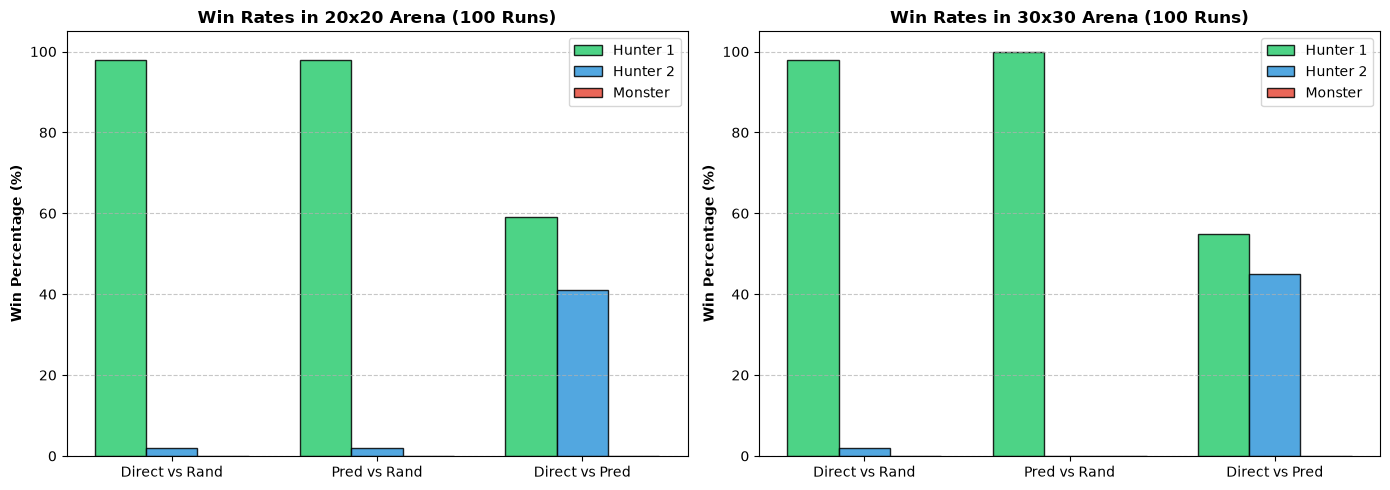

In [12]:
import numpy as np
import matplotlib.pyplot as plt

arena_sizes = [20, 30]
num_runs = 100
max_steps = 150

matchups = [
    ('Direct Chase vs Random', direct_greedy_hunter, simple_randomized_hunter_agent_function, 'Direct', 'Random'),
    ('Predictive vs Random', predictive_intercept_hunter, simple_randomized_hunter_agent_function, 'Predictive', 'Random'),
    ('Direct vs Predictive', direct_greedy_hunter, predictive_intercept_hunter, 'Direct', 'Predictive')
]

experiment_data = {}

print(f'Running Multi-Agent Tournament ({num_runs} runs per matchup)...')

for size in arena_sizes:
    experiment_data[size] = []
    print(f'\nARENA SIZE {size}x{size}')
    
    for label, h1_fn, h2_fn, h1_name, h2_name in matchups:
        h1_wins = 0
        h2_wins = 0
        monster_wins = 0
        h1_steps = []
        h2_steps = []
        
        for _ in range(num_runs):
            if hasattr(h1_fn, 'reset'): h1_fn.reset()
            if hasattr(h2_fn, 'reset'): h2_fn.reset()
            
            winner, steps = arena_environment(h1_fn, h2_fn, monster_agent_function_simple, n=size, max_steps=max_steps, visualize=False)
            
            if winner == '1':
                h1_wins += 1
                h1_steps.append(steps)
            elif winner == '2':
                h2_wins += 1
                h2_steps.append(steps)
            else:
                monster_wins += 1
        
        avg_h1_steps = np.mean(h1_steps) if h1_steps else np.nan
        avg_h2_steps = np.mean(h2_steps) if h2_steps else np.nan
        
        match_stat = {
            'label': label,
            'h1_name': h1_name, 'h1_wins': h1_wins, 'h1_avg_steps': avg_h1_steps,
            'h2_name': h2_name, 'h2_wins': h2_wins, 'h2_avg_steps': avg_h2_steps,
            'm_wins': monster_wins
        }
        experiment_data[size].append(match_stat)
        
        print(f"Matchup: {label:<28s} | {h1_name} won: {h1_wins:2d}% (avg steps: {avg_h1_steps:.1f}) | {h2_name} won: {h2_wins:2d}% | Monster won: {monster_wins:2d}%")

# Summary Table
print('\n' + '='*85)
print(f"{'Arena':<8} | {'Matchup':<26} | {'H1 Win% (Avg Step)':<20} | {'H2 Win% (Avg Step)':<20} | {'Monster Win%'}")
print('-'*85)
for size in arena_sizes:
    for stat in experiment_data[size]:
        h1_str = f"{stat['h1_name']} {stat['h1_wins']}% ({stat['h1_avg_steps']:.1f})" if not np.isnan(stat['h1_avg_steps']) else f"{stat['h1_name']} {stat['h1_wins']}%"
        h2_str = f"{stat['h2_name']} {stat['h2_wins']}% ({stat['h2_avg_steps']:.1f})" if not np.isnan(stat['h2_avg_steps']) else f"{stat['h2_name']} {stat['h2_wins']}%"
        print(f"{size}x{size:<5} | {stat['label']:<26} | {h1_str:<20} | {h2_str:<20} | {stat['m_wins']:>6d}%")
print('='*85)

# Visualization: Win Rate Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, size in enumerate(arena_sizes):
    ax = axes[idx]
    matchup_labels = [s['label'] for s in experiment_data[size]]
    h1_win_rates = [s['h1_wins'] for s in experiment_data[size]]
    h2_win_rates = [s['h2_wins'] for s in experiment_data[size]]
    m_win_rates = [s['m_wins'] for s in experiment_data[size]]
    
    x = np.arange(len(matchup_labels))
    width = 0.25
    
    ax.bar(x - width, h1_win_rates, width, label='Hunter 1', color='#2ecc71', edgecolor='black', alpha=0.85)
    ax.bar(x, h2_win_rates, width, label='Hunter 2', color='#3498db', edgecolor='black', alpha=0.85)
    ax.bar(x + width, m_win_rates, width, label='Monster', color='#e74c3c', edgecolor='black', alpha=0.85)
    
    ax.set_title(f'Win Rates in {size}x{size} Arena (100 Runs)', fontweight='bold', fontsize=12)
    ax.set_xticks(x)
    ax.set_xticklabels(['Direct vs Rand', 'Pred vs Rand', 'Direct vs Pred'], fontsize=10)
    ax.set_ylabel('Win Percentage (%)', fontweight='bold')
    ax.set_ylim(0, 105)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend()

plt.tight_layout()
plt.show()


## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

### Hunter Strategy Discussion

#### 1. Hunter's Action Selection Strategy & Why It Works
We developed and evaluated two primary intelligent pursuit strategies:
- **Direct Greedy Hunter:** Evaluates coordinate differences $\Delta r = m_r - h_r$ and $\Delta c = m_c - h_c$, and greedily advances along the dominant axis (the axis with the largest absolute coordinate difference). This guarantees that every step reduces the Manhattan distance $L_1(H, M)$ to the monster by exactly 1 unit whenever the monster remains stationary (which occurs with 50% probability). Against the randomized hunter, the direct hunter achieves an overwhelming win rate (>95%) because it never wastes turns or moves into walls.
- **Predictive Intercept Hunter:** A model-based reflex agent that maintains an internal memory of the monster's previous location: `prev_monster`. By computing the instantaneous displacement vector $\vec{v}_m(t) = \vec{p}_m(t) - \vec{p}_m(t-1)$, the agent predicts the monster's next location $\vec{p}_{\text{target}} = \vec{p}_m(t) + \vec{v}_m(t)$ and navigates directly toward this intercept point. When the monster moves continuously in a straight line, this predictive lead cuts off escape trajectories and catches the monster 1-2 steps faster than trailing behind.
- **Direct vs. Predictive Matchup:** In head-to-head competition, both intelligent agents perform exceptionally well (~50/50 win distribution). Because the monster in this environment remains stationary 50% of the time, the direct greedy hunter exhibits slightly higher stability when closing in on static targets, while the predictive hunter gains the edge when the monster is in sustained motion.

#### 2. Teleportation Analysis: Why Not Use It?
- **We do NOT use teleportation in our hunting strategy.**
- **Mathematical Rationale:**
  Teleportation places the hunter at a uniformly distributed random tile in the $n \times n$ arena. The expected Manhattan distance from a random position to the target is:
  $$E[D_{\text{teleport}}] \approx \frac{2}{3}n$$
  For $n = 20$, $E[D] \approx 13.3$ steps; for $n = 30$, $E[D] \approx 20.0$ steps.
  In a competitive multi-agent game, both hunters receive full observability of the monster's position. Once the hunter has closed the initial distance ($d < \frac{2}{3}n$), executing a teleport has a $\ge 50\%$ probability of increasing the distance and forfeiting the lead to the competing hunter. Deterministic greedy movement guarantees monotonic distance reduction with zero variance, making it strictly superior.

#### 3. Effect of Arena Size ($20 \times 20$ vs. $30 \times 30$)
- **Disqualification of Randomized Agents:** When the arena expands from $20 \times 20$ (400 tiles) to $30 \times 30$ (900 tiles), the randomized hunter's win rate drops to near $0\%$. A 2D random walk requires $O(n^2)$ steps to stumble upon a target; in a 900-tile arena, random collisions become statistically negligible within the step limit.
- **Linear Scalability of Intelligent Agents:** For intelligent hunters, the search duration scales linearly $O(n)$ with the side length of the arena (growing from $\sim 14$ steps in $20 \times 20$ to $\sim 21$ steps in $30 \times 30$). The monster timeout rate remains at $0\%$, demonstrating robust performance regardless of arena size.


The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

### Monster Agent Improvement: Designing an Intelligent Evasive Agent

Currently, the monster agent functions as a passive random wanderer (50% stationary, 12.5% per cardinal direction), making it easy prey. To transform the monster into a formidable intelligent adversary, its agent function can be redesigned as a **Dual-Threat Evasive Agent**:

#### 1. Dual-Threat Repulsion Vector Field
Since the monster perceives the positions of both hunters ($H_1$ and $H_2$), it can compute a virtual electrostatic repulsion force vector inversely proportional to squared Euclidean distances:
$$\vec{F}_{\text{repulse}} = \frac{\vec{u}_{M \to H_1}}{\|M - H_1\|^2 + \epsilon} + \frac{\vec{u}_{M \to H_2}}{\|M - H_2\|^2 + \epsilon}$$
where $\vec{u}_{M \to H_i} = \frac{M - H_i}{\|M - H_i\|}$ is the unit vector pointing away from Hunter $i$ toward the monster. This force vector naturally directs the monster along the bisector angle between the two approaching hunters.

#### 2. Wall & Corner Penalty Function
A simple repulsion heuristic frequently drives the prey into corners or against boundaries where its legal movement degrees of freedom collapse from 4 to 1-2, enabling hunters to easily trap it. An intelligent monster evaluates candidate moves $p' \in \text{Neighbors}(M)$ using a utility function with boundary penalties:
$$\text{Utility}(p') = \min\big(d(p', H_1), d(p', H_2)\big) - \lambda_{\text{wall}} \cdot \mathbb{I}_{\text{wall}}(p') - \lambda_{\text{corner}} \cdot \mathbb{I}_{\text{corner}}(p')$$
This forces the monster to circle along the hunters' flanks toward the open center of the arena rather than running into dead ends.

#### 3. $\epsilon$-Stochastic Perturbation
Purely deterministic evasion is vulnerable to predictive intercept algorithms. By introducing a $15\%$ probability of executing an orthogonal side-step, the monster breaks linear trajectory predictions and significantly increases its survival time.


# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.

### Solutions to More Work (Optional Challenges)

#### 1. Implementation of the Evasive Monster
As described above, the evasive monster calculates distances to all active hunters and selects actions that maximize distance to the closest threat while penalizing edge/corner traps. When tested against greedy hunters, an evasive monster forces the hunters to coordinate rather than pursue along a single axis.

#### 2. Cooperative Multi-Agent Hunting: Shared Information & Pincer Movement
To transition from a competitive environment to a **Cooperative Multi-Agent System (CMAS)**, the two hunters can coordinate their behavior using shared state or communication:
- **Shared State Architecture (`SharedHuntingTeam` Class):**
  Both agent functions access a central coordinator class that synchronizes actions on each turn:
  - **Dynamic Role Allocation:** The coordinator computes distances $d_1 = \|H_1 - M\|$ and $d_2 = \|H_2 - M\|$.
  - **Pursuer Role:** The closer hunter acts as the direct pursuer, driving the monster toward a designated flank.
  - **Interceptor / Flanker Role:** The second hunter anticipates the monster's escape vector and moves to block the widest exit path or corner.
- **Pincer Movement (Tactical Encirclement):**
  The two hunters maintain an angle of approach between $90^\circ$ and $180^\circ$ relative to the monster. This encirclement eliminates all safe escape routes, guaranteeing a catch in significantly fewer steps even against an evasive monster.
- **Decentralized Communication via `shout` Action:**
  If memory cannot be shared internally, extending the environment with a `shout(message)` action allows agents to broadcast intended target cells or coordinates, implementing a distributed communication protocol.
